# Рекуррентный график цены Bitcoin

Ноутбук заново собирает рисунок из поста: тёмный график, heatmap в палитре viridis, шкала **Recurrence** от 0 до 1, линия цены и красные пунктиры в даты халвингов. Заголовок графика — `Recurrence Graph of Bitcoin Price Patterns`.

Оба оси heatmap — календарное время. Яркость точки `(t, s)` — это рекуррентность: насколько близки логарифмы цены в дни `t` и `s`. Похожие блоки означают похожий ценовой режим, а не торговый сигнал. Диагональ всегда равна 1, потому что день сравнивается сам с собой. Вне диагонали блоки возникают там, где цена позже возвращается в уже виденный диапазон. После каждого халвинга эти блоки выглядят иначе: рынок проводит время в других диапазонах.

Это описание публичного ряда цены. Ноутбук ничего не прогнозирует и не предлагает сделок.


## Как запустить

Из корня репозитория:

```bash
pip install -r requirements.txt
jupyter nbconvert --to notebook --execute --inplace notebooks/bitcoin_recurrence.ipynb
```

Тот же результат даёт Run All в Jupyter. Нужен выход в сеть: дневные цены скачиваются с Blockchain.com (см. ячейку с данными). Рисунок сохраняется в `notebooks/bitcoin_recurrence.png` и остаётся в выводе ноутбука.


## Параметры

Все величины, от которых зависит рисунок, задаются в следующей ячейке.

- `START`, `END` — окно, которое на посте занимает ось примерно с 2012 по август 2024. Халвинг 2024-04-20 остаётся внутри правого края, а не на нём.
- `PERCENTAGE` — какой процентиль попарных расстояний берётся за масштаб сходства `epsilon`. В черновике для бинарного графика стояли 2 и 3. Для непрерывной шкалы поста подходит 2: при 3 блоки заливаются жёлтым и теряют голубую кайму.
- Ресемплинг не нужен: ряд уже дневной.
- `CMAP` — `viridis`, как на посте: низкие значения фиолетовые, высокие жёлтые.


In [1]:
# Окно ряда. Конец совпадает с последней датой, которая была в сохранённом выводе старого ноутбука.
START = "2012-01-01"
END = "2024-08-25"

# Масштаб сходства: epsilon = этот процентиль |log price_i - log price_j|.
# 2 — значение из черновика (ячейки с percentage=2). Бинарный порог 3% даёт сплошные жёлтые блоки.
PERCENTAGE = 2.0

# Вложение, как в pyts.image.RecurrencePlot по умолчанию и в финальных ячейках черновика:
# состояние дня — само значение log(Close), без задержки.
DIMENSION = 1
TIME_DELAY = 1

CMAP = "viridis"

# Линия цены. В черновике было white с alpha 0.2; на фиолетовом поле это бледная линия.
# Чуть более плотный светлый голубой читается и в легенде Bitcoin Price, и на heatmap.
PRICE_COLOR = "#b9f3ff"
PRICE_ALPHA = 0.55

# Даты халвингов из черновика.
HALVING_DATES = ("2012-11-28", "2016-07-09", "2020-05-11", "2024-04-20")


## Данные

Старый ноутбук сначала звал `yfinance` для `BTC-USD` с 2010-01-01, но у Yahoo этот тикер начинается 2014-09-17, поэтому халвинг 2012 года на такой ряд не попадает. Следующая ячейка черновика читала локальный `BTC_1d.csv`, которого в репозитории нет.

Здесь ряд берётся из публичного дневного графика [Blockchain.com Charts: market price](https://api.blockchain.info/charts/market-price) (`timespan=all`, `sampled=false`). Это одна цена в сутки, без пропусков, в долларах. Для рисунка оставляем `START`…`END`. Файл в репозиторий не кладётся: запрос стабильно отдаёт историю.


In [2]:
import json
import urllib.request
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BLOCKCHAIN_URL = (
    "https://api.blockchain.info/charts/market-price"
    "?timespan=all&sampled=false&format=json"
)


def download_market_price(url: str = BLOCKCHAIN_URL) -> pd.DataFrame:
    """Дневная цена BTC/USD с Blockchain.com. Индекс — дата, колонка Close."""
    request = urllib.request.Request(url, headers={"User-Agent": "bitcoin-recurrence-notebook"})
    with urllib.request.urlopen(request, timeout=60) as response:
        payload = json.load(response)
    frame = pd.DataFrame(payload["values"])
    frame["date"] = pd.to_datetime(frame["x"], unit="s", utc=True).dt.tz_localize(None)
    close = (
        frame.set_index("date")
        .sort_index()["y"]
        .astype(float)
        .rename("Close")
    )
    close = close[~close.index.duplicated(keep="last")]
    return close.to_frame()


prices = download_market_price()
close = prices.loc[START:END, "Close"]
close = close[close > 0]
if close.empty:
    raise RuntimeError(f"В окне {START} … {END} нет положительных цен.")

print(
    f"{len(close)} дней, {close.index[0].date()} — {close.index[-1].date()}, "
    f"первая цена {close.iloc[0]:.2f} USD, последняя {close.iloc[-1]:.2f} USD"
)
close.head()


4621 дней, 2012-01-01 — 2024-08-25, первая цена 5.04 USD, последняя 64174.59 USD


date
2012-01-01    5.04
2012-01-02    5.27
2012-01-03    5.45
2012-01-04    5.37
2012-01-05    5.80
Name: Close, dtype: float64

## Рекуррентность

Черновик считал матрицу через `pyts.image.RecurrencePlot`. При `dimension=1` и `time_delay=1` расстояние — модуль разности ряда. Ряд там — `log(Close)`. Порог `threshold='point'` оставляет единицы только у пар ближе заданного процентиля, остальные нули.

На посте шкала непрерывная, от 0 до 1, а блоки голубые и зелёные, не сплошь жёлтые. Поэтому та же дистанция отображается мягко:

\[ R_{ij} = \exp\left(-\frac{|\log p_i - \log p_j|}{\varepsilon}\right) \]

\(\varepsilon\) — процентиль `PERCENTAGE` всех попарных расстояний. На диагонали \(R=1\). Далеко разошедшиеся режимы уходят к 0. Это не бинарная маска из черновика; процентиль тот же, что там выбирали как `percentage`.


In [3]:
def log_price_distance(close_prices: pd.Series) -> np.ndarray:
    """Попарный |log p_i - log p_j|. То же расстояние, что у RecurrencePlot(dimension=1)."""
    log_price = np.log(close_prices.to_numpy(dtype=np.float64))
    return np.abs(log_price[:, None] - log_price[None, :])


def continuous_recurrence(distance: np.ndarray, percentage: float) -> tuple[np.ndarray, float]:
    """Непрерывная рекуррентность в (0, 1]. epsilon — процентиль расстояний."""
    if not 0 < percentage <= 100:
        raise ValueError("PERCENTAGE должен быть в (0, 100].")
    epsilon = float(np.percentile(distance, percentage))
    if epsilon <= 0:
        raise RuntimeError("epsilon получился нулевым, ряд слишком короткий или постоянный.")
    recurrence = np.exp(-distance / epsilon)
    return recurrence, epsilon


distance = log_price_distance(close)
recurrence, epsilon = continuous_recurrence(distance, PERCENTAGE)
print(
    f"epsilon = {epsilon:.4f} в единицах log-цены "
    f"(около {(np.exp(epsilon) - 1) * 100:.2f}% по цене), "
    f"матрица {recurrence.shape[0]}×{recurrence.shape[1]}, "
    f"min {recurrence.min():.3f}, max {recurrence.max():.3f}"
)


epsilon = 0.0520 в единицах log-цены (около 5.34% по цене), матрица 4621×4621, min 0.000, max 1.000


## Рисунок

Подписи осей, легенда и colorbar — по-английски, как на посте. Годы стоят только на горизонтальной оси: вертикальная ось — то же время, но в посте отдельные подписи лет слева не показаны. Линия цены на логарифмической шкале, без своих цифр, чтобы не спорить с осью времени.


saved /workspace/notebooks/bitcoin_recurrence.png


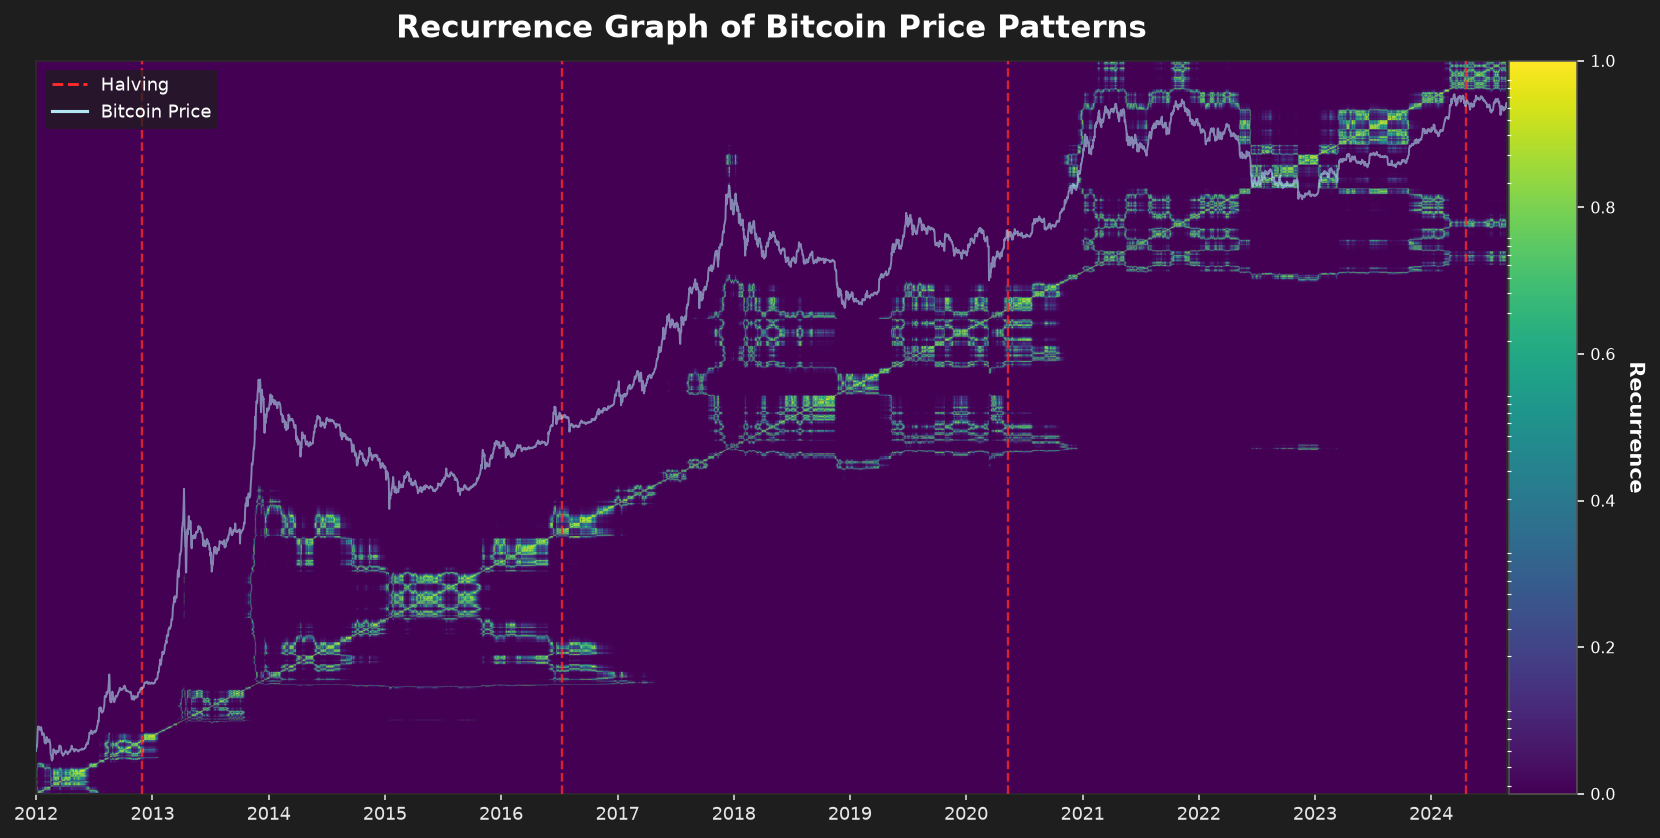

In [4]:
def figure_path() -> Path:
    """PNG рядом с ноутбуком и при запуске из корня репозитория, и из notebooks/."""
    notebooks_dir = Path("notebooks")
    if notebooks_dir.is_dir():
        return notebooks_dir / "bitcoin_recurrence.png"
    return Path("bitcoin_recurrence.png")


halvings = pd.to_datetime(list(HALVING_DATES))
left = mdates.date2num(close.index[0])
right = mdates.date2num(close.index[-1])

plt.style.use("dark_background")
fig = plt.figure(figsize=(14.2, 6.8), dpi=140)
fig.patch.set_facecolor("#1E1E1E")
grid = fig.add_gridspec(1, 22, wspace=0.04)
ax = fig.add_subplot(grid[0, :21])
color_ax = fig.add_subplot(grid[0, 21])

image = ax.imshow(
    recurrence,
    cmap=CMAP,
    vmin=0,
    vmax=1,
    origin="lower",
    aspect="auto",
    interpolation="antialiased",
    extent=(left, right, left, right),
)
ax.set_title(
    "Recurrence Graph of Bitcoin Price Patterns",
    fontsize=16,
    fontweight="bold",
    color="white",
    pad=12,
)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.tick_params(axis="x", labelsize=9, colors="#e6e6e6", length=3)
ax.tick_params(axis="y", labelleft=False, length=0)
for spine in ax.spines.values():
    spine.set_color("#2c2c2c")

price_ax = ax.twinx()
price_ax.plot(
    close.index,
    close.to_numpy(),
    color=PRICE_COLOR,
    alpha=PRICE_ALPHA,
    linewidth=1.0,
    zorder=5,
)
price_ax.set_yscale("log")
price_ax.set_yticks([])
for spine in price_ax.spines.values():
    spine.set_visible(False)

for halving in halvings:
    if close.index[0] <= halving <= close.index[-1]:
        ax.axvline(
            mdates.date2num(halving),
            color="#ff2a2a",
            linestyle="--",
            linewidth=1.2,
            alpha=0.8,
            zorder=4,
        )

halving_handle, = ax.plot([], [], color="#ff2a2a", linestyle="--", linewidth=1.5, label="Halving")
price_handle, = price_ax.plot([], [], color=PRICE_COLOR, linewidth=1.6, alpha=0.95, label="Bitcoin Price")
legend = ax.legend(
    handles=[halving_handle, price_handle],
    loc="upper left",
    fontsize=9,
    facecolor="#1E1E1E",
    edgecolor="none",
    framealpha=0.75,
)
for text in legend.get_texts():
    text.set_color("white")

# Фиксируем окно времени: линия цены не должна раздвигать ось и сдвигать халвинги.
ax.set_xlim(left, right)
ax.set_ylim(left, right)

colorbar = fig.colorbar(image, cax=color_ax)
colorbar.set_ticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
colorbar.set_label("Recurrence", rotation=270, labelpad=16, fontsize=11, fontweight="bold", color="white")
colorbar.ax.tick_params(colors="white", labelsize=8)
colorbar.outline.set_edgecolor("#555555")

png_path = figure_path()
fig.savefig(png_path, dpi=140, bbox_inches="tight", facecolor=fig.get_facecolor())
print(f"saved {png_path.resolve()}")
plt.show()


## Как читать рисунок и что сознательно отличается от черновика

Яркая диагональ — совпадение дня с самим собой. Квадраты и «шахматки» вдоль неё — отрезки, когда цена несколько недель или месяцев остаётся в узком диапазоне: такие дни рекуррентны друг другу. Отдельные блоки в стороне от диагонали — возврат к старому уровню. Пустая фиолетовая область внизу справа — ранние дешёвые годы против поздних дорогих: по логарифму цены они далеки, рекуррентность около нуля.

Красные линии — халвинги 2012-11-28, 2016-07-09, 2020-05-11 и 2024-04-20. По разные стороны линии блоки устроены по-разному. Это наблюдение по картинке, не вывод о причине.

Допущения относительно старого ноутбука:

- Дистанция и ряд те же: `|log Close_i - log Close_j|`, вложение размерности 1 без задержки. Отдельные ячейки черновика пробовали `dimension=20` и `time_delay` в сотни дней; финальный график с этим заголовком использовал размерность 1.
- Черновик бинаризовал матрицу (`threshold='point'`). Пост показывает непрерывную шкалу 0…1 и голубо-зелёные блоки. Здесь оставлена непрерывная экспонента с `epsilon` на 2-м процентиле расстояний. Бинарный порог 3% из ячейки с тем же заголовком даёт сплошные жёлтые прямоугольники и хуже совпадает с постом.
- Источник цены — Blockchain.com, окно 2012-01-01 … 2024-08-25. Положения четырёх халвингов на оси при этом совпадают с постом. Yahoo `BTC-USD` так не умеет: ряд короче слева.
- Линия цены бледная и на логарифмической шкале, как `set_yscale('log')` и полупрозрачный `plot` в черновике. Цвет чуть голубой, чтобы легенда Bitcoin Price совпадала с подписью поста.
- Водяной знак, который виден на скриншоте поста, не рисуется. Скругление карточки в ленте — рамка публикации, не часть matplotlib-рисунка.
